In [1]:
import pandas as pd
import numpy as np


# 1. Data Loading and Understanding

The dataset used in this project is the Planetary Systems Composite Parameters table obtained from the NASA Exoplanet Archive.

It contains information about confirmed exoplanets, including their physical properties, orbital characteristics, and host stars.

In [2]:
df = pd.read_csv("data.csv", comment="#")

print("Number of planets = ",df.shape[0])
print("Number of features: = ",df.shape[1])

Number of planets =  6451
Number of features: =  84


# EXPLORATORY DATA ANALYSIS

1) Cleaning up irrelevant and inusable data
2) Plotting a graph for equilbirum temp vs frequency for possible patterns 
3) Plottting a graph for each eq temp vs used features


In [3]:


#Cleaning up data

df = df[(df["pl_eqt"] > 50) & (df["pl_eqt"] < 3000) & (df["pl_orbsmax"] > 0.001) & (df["pl_orbsmax"] < 20)].copy()
df=df.dropna(subset=["pl_eqt"])
features = ["st_teff","st_rad","pl_orbsmax"]

target = "pl_eqt"
df=df.dropna(subset=features)


print("Observations available for EDA:", len(df))

Observations available for EDA: 5538


#plotting possible useful graphs

<Axes: title={'center': 'distribution of exoplanet temperatures'}, ylabel='Frequency'>

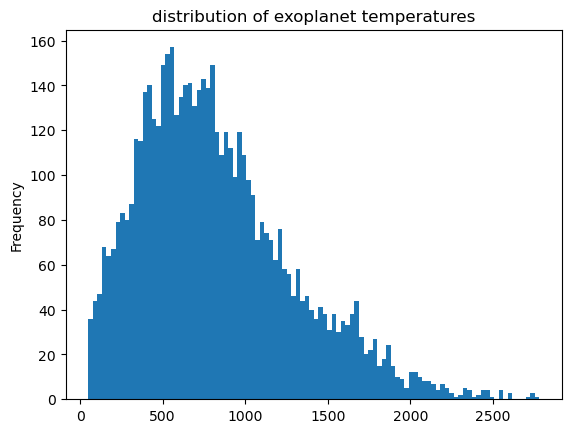

In [4]:
df["pl_eqt"].plot(kind="hist",bins=100,title="distribution of exoplanet temperatures")

In [5]:
#displaying correlations with target column(equilibirum temp)

df_num = df.select_dtypes(include=np.number)

corr = df_num.corr()


print(corr["pl_eqt"].sort_values(ascending=False).head(10))
print(corr["pl_eqt"].sort_values(ascending=True).head(10))

pl_eqt            1.000000
pl_insol          0.611908
pl_insolerr1      0.449065
st_mass           0.304276
pl_eqterr1        0.301282
st_teff           0.282361
sy_kmag           0.190190
pl_orbsmaxerr2    0.187806
sy_dist           0.184409
pl_orbeccenlim    0.162782
Name: pl_eqt, dtype: float64
pl_insolerr2     -0.488116
pl_orbsmax       -0.328487
pl_eqterr2       -0.292701
pl_orbeccen      -0.249485
pl_orbper        -0.243010
sy_pnum          -0.180389
pl_orbsmaxerr1   -0.177084
st_logg          -0.152580
st_tefferr2      -0.135457
pl_radeerr2      -0.131517
Name: pl_eqt, dtype: float64


<Axes: title={'center': 'stellar temperature(st_teff) vs (pl_eqt)equilibrium temperature'}, xlabel='st_teff', ylabel='pl_eqt'>

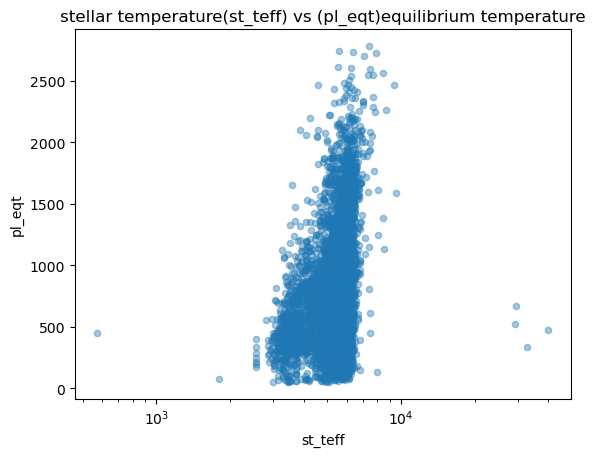

In [6]:
df.plot(kind="scatter",x="st_teff",y="pl_eqt",alpha=0.4,logx=True,title="stellar temperature(st_teff) vs (pl_eqt)equilibrium temperature")

<Axes: title={'center': 'orbital distance(pl_orbsmax) vs equilibrium temperature(pl_eqt)'}, xlabel='pl_orbsmax', ylabel='pl_eqt'>

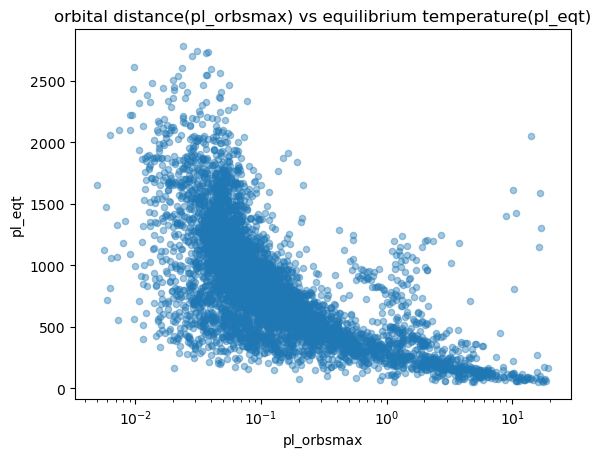

In [7]:
df.plot(kind="scatter",x="pl_orbsmax",y="pl_eqt",alpha=0.4,logx=True,title="orbital distance(pl_orbsmax) vs equilibrium temperature(pl_eqt)")

<Axes: title={'center': 'star radius(st_rad) vs (pl_eqt)equilibrium temperature'}, xlabel='st_rad', ylabel='pl_eqt'>

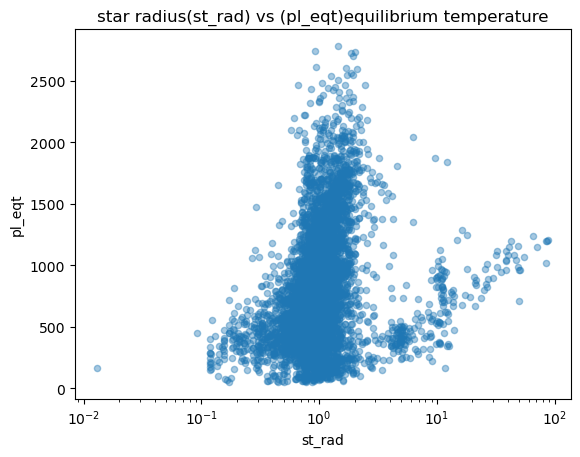

In [8]:
df.plot(kind="scatter",x="st_rad",y="pl_eqt",alpha=0.4,logx=True,title="star radius(st_rad) vs (pl_eqt)equilibrium temperature")

## Observations from EDA

1. Temperature Distribution: This shows the max number of planets will have a temperature roughly between 400 - 1000 K.

2. Star Radius (st_rad): Shows a dense vertical cluster around 1 solar radius with no well-defined linear trend, confirming it as a weak secondary predictor. 

3. Orbital Distance (pl_orbsmax): Displays a strong inverse relationship where planetary temperatures drop sharply as distance increases.  

4. Stellar Temperature (st_teff): Centered around Sun-like stars 5,000 K – 6,000 K, also showing a SOMEWHAT weak linear relationship.

## 3. Data preprocessing


1) Splitting the dataset into training and testing sets.
2) Applying logarithmic transformation 
3) Standardisation into operable data


In [9]:
#splitting into training and testing data

rng=np.random.default_rng(0) 
shuffled=rng.permutation(len(df))
split=int(0.8*len(df))

df_test=df.iloc[shuffled[split:]].copy()
df=df.iloc[shuffled[:split]].copy()

# Standardisation

The selected features have different numerical scales. To make gradient descent work more effectively, the input features are first transformed using the natural logarithm and then standardised.

The standardisation formula is:

x(scaled) = (x-mean)/(standard deviation)

In this formula, all elements are vectors made from numpy for effiecient calculation


The mean and standard deviation are calculated using only the training dataset to prevent information from the testing dataset from influencing the training process (AKA data leakage).

In [10]:
logged = np.log(df[features])
mean=logged.mean()
sigma=logged.std()
scaled = (logged - mean) / sigma

x = scaled[features].to_numpy(dtype=float)
y = np.log(df[target].to_numpy(dtype=float))

## 4. Linear Regression Implementation



The prediction equation used to predict temperature is:

y = w(1)x(1) + w(2)x(2) + w(3)x(3) + b

Where:

1) w represents the weights (coefficients).
2) x represents the input features.
3) b represents the bias.
4) y represents the predicted logarithm of equilibrium temperature.

The model parameters are repetitevly optimised using Gradient Descent until the lowest value of Mean Squared Error (MSE) is reached.

The gradients are calculated using vectors in NumPy instead of explicit loops, making the computation more efficient.
(NOTE : It was insanely faster than using for loops)

In [11]:
# singular adjustment function using GD

def grad_desc(x,y,L,wnew,bnew):
    wgrad=np.zeros(len(x[0]))
    bgrad=0

    n = len(y)

    pred = x@wnew + bnew
    bgrad = -(2/n) * np.sum(y - pred)
    wgrad = -(2/n) * (x.T@( y - pred))

    wnew -= wgrad * L
    bnew -= bgrad * L

    return wnew, bnew

In [12]:
#training the model

w=np.zeros(len(x[0]))
b=0.0 #float important

for i in range(10000):
   
    w,b = grad_desc(x,y,0.01,w,b)

## Converting back into original scale

Since the input features were standardised and logarithmically transformed, the learned coefficients cannot be directly uesd and plotted in their original feature scales.

The final predictions are then converted back into Kelvin using the exponential function.

In [13]:
w_orig = w / sigma.to_numpy()
b_orig = b - np.sum(w * mean.to_numpy() / sigma.to_numpy())



print("weights:")
display(w_orig)
print("bias:", b_orig)

weights:


array([ 0.91858383,  0.49286601, -0.47572375])

bias: -2.3225329318176895


In [14]:
predicted = np.exp(logged.to_numpy(dtype=float)@w_orig + b_orig)
actual = np.exp(y)

# Model Evaluation

The trained model is evaluated using the testing dataset, which was not used during training to prevent data leakage.

Three evaluation criterias were used:

1) Mean Absolute Error (MAE) =  MAE = 1/n * sum of (|y-pred|/y)

2) Root Mean Squared Error (RMSE) = root of (1/n * sum of ((y - pred)**2))

3) R² Score = (SSR/SST) 

where SST = sum of (y - mean(y))**2
and SSR = sum of (y y - mean(y)**2)

All three were calculated using vectors in numpy for max affieciency.

In [15]:
#testing with remaining data

lt = np.log(df_test[features])
yt = np.log(df_test[target].to_numpy(dtype=float))

pred_test = np.exp(lt.to_numpy(dtype=float)@w_orig + b_orig)
act_test = np.exp(yt)

SSR = np.sum((act_test - pred_test)**2)
SST = np.sum((act_test - act_test.mean())**2)
MAE = np.mean(np.abs(act_test - pred_test))

RMSE = np.sqrt(np.mean((act_test - pred_test)**2))

print("MAE:", MAE, "K")
print("RMSE:", RMSE, "K")
print("Test R²:", 1 - SSR/SST)

MAE: 54.87237770145195 K
RMSE: 106.31094511553577 K
Test R²: 0.9451046337942675


<Axes: title={'center': 'actual vs predicted equilibrium temperature'}, xlabel='actual temperature', ylabel='predicted temperature'>

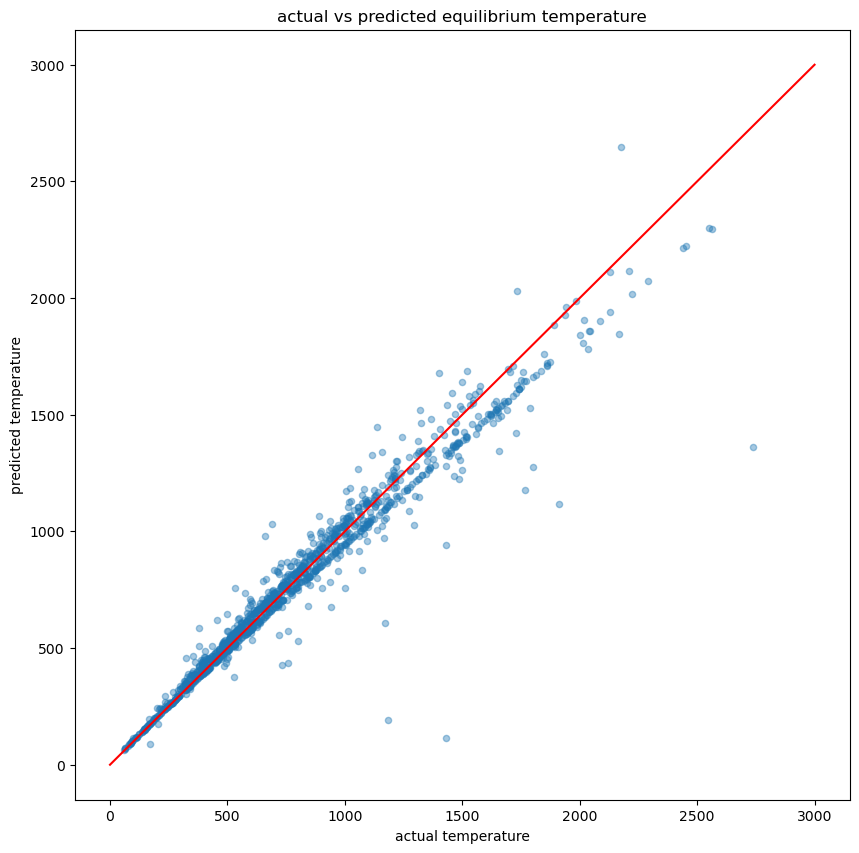

In [16]:
#code for plot of predicted vs actual temp

comparison = pd.DataFrame({"actual temperature": act_test,"predicted temperature": pred_test
})

ax = comparison.plot(
    kind="scatter",
    x="actual temperature",
    y="predicted temperature",
    figsize=(10, 10),
    alpha=0.4,
    title="actual vs predicted equilibrium temperature"
)

pd.Series([0, 3000],index=[0, 3000]).plot(color="red")

The general trend of the points is following the line y=x. Which means the predicted temperatures are close to eactual temperatures for most cases 

In [17]:
#printing the hottest and coldest planets

results = df_test[["pl_name"]].copy()
results["predicted temperature (K)"] = pred_test
results["actual temperature (K)"] = act_test

hottest = results["predicted temperature (K)"].idxmax()

coldest = results["predicted temperature (K)"].idxmin()

print("HOTTEST PREDICTED PLANET")
print(results.loc[hottest])
print("\n")
print("COLDEST PREDICTED PLANET")
print(results.loc[coldest])

HOTTEST PREDICTED PLANET
pl_name                      Kepler-1340 b
predicted temperature (K)      2647.880265
actual temperature (K)              2174.0
Name: 2649, dtype: object


COLDEST PREDICTED PLANET
pl_name                      HD 222237 b
predicted temperature (K)       63.65582
actual temperature (K)             58.74
Name: 1012, dtype: object
